# From a modelgami model to MCMC draws in ArviZ

This notebook takes a model, turns it into an unconstrained log density with its gradient, samples it with BlackJAX's NUTS, and converts the array of unconstrained MCMC samples into structured draws in ArviZ.

The model is the conjugate Bayesian regression from `modelgami.examples`: $y \sim N(X\beta, \sigma^2 I)$ with $\beta \mid \sigma^2 \sim N(m_0, \sigma^2 V_0)$ and $\sigma^2 \sim \text{InvGamma}(a_0, b_0)$. Its posterior is known exactly, so we can check the sampler.

Run `./setup_venv.sh` in this folder once and register the kernel it prints; this notebook uses that kernel ("Python (modelgami)").

In [1]:
import jax
import jax.numpy as jnp
import numpy as np
import blackjax
import arviz as az

import modelgami as mg
from modelgami.examples import conjugate_regression as cr

jax.config.update("jax_enable_x64", True)

X, y = cr.simulate_data(jax.random.PRNGKey(0), n=100, p=3)
model = cr.make_model(X, y)
model.params_pattern

PatternDict(patterns={'beta': ('NumericVectorPattern', {'shape': (3,), 'lb': -inf, 'ub': inf, 'order': 'C'}), 'sigma2': ('NumericScalarPattern', {'shape': (), 'lb': 0.0, 'ub': inf, 'order': 'C'})})

## 1. The unconstrained log density and its gradient

BlackJAX samples on $\mathbb{R}^d$, so we use the free representation. The joint density in free form includes the log Jacobian by default, which is what a sampler needs. BlackJAX computes the gradient itself with `jax.grad`; we show it here only to make the point.

In [2]:
logdensity = model.log_density_fn("joint", params_as="free")
grad_logdensity = jax.grad(logdensity)

x0 = model.flatten_params(model.random_params(jax.random.PRNGKey(1)), to_free=True)
print("dimension:", model.free_dim)
print("log density:", logdensity(x0))
print("gradient:", grad_logdensity(x0))

dimension: 4


log density: -215.09841454974014


gradient: [-0.89084769 52.48764625 20.75100342 13.66422827]


## 2. NUTS with BlackJAX

We run window adaptation (step size and diagonal mass matrix) separately for each of four chains, then sample. Each chain is one `vmap`ped call.

In [3]:
n_chains, n_warmup, n_draws = 4, 1000, 1000

def run_chain(key, x_init):
    warmup_key, sample_key = jax.random.split(key)
    warmup = blackjax.window_adaptation(blackjax.nuts, logdensity)
    (state, tuned), _ = warmup.run(warmup_key, x_init, num_steps=n_warmup)
    step = blackjax.nuts(logdensity, **tuned).step

    def one_step(state, key):
        state, info = step(key, state)
        return state, (state.position, info.is_divergent)

    _, (positions, divergent) = jax.lax.scan(one_step, state, jax.random.split(sample_key, n_draws))
    return positions, divergent

init_keys = jax.random.split(jax.random.PRNGKey(2), n_chains)
x_inits = jax.vmap(lambda k: model.flatten_params(model.random_params(k), to_free=True))(init_keys)
chain_keys = jax.random.split(jax.random.PRNGKey(3), n_chains)

free_draws, divergent = jax.jit(jax.vmap(run_chain))(chain_keys, x_inits)
print("free draws:", free_draws.shape, "(chain, draw, free dimension)")
print("divergences:", int(divergent.sum()))

free draws: (4, 1000, 4) (chain, draw, free dimension)


divergences: 0


## 3. From unconstrained arrays to structured draws

The pattern folds one free vector into a dict of constrained parameters. Two `vmap`s fold every draw of every chain.

In [4]:
fold = lambda x: model.fold_params(x, from_free=True)
draws = jax.vmap(jax.vmap(fold))(free_draws)
{k: v.shape for k, v in draws.items()}

{'beta': (4, 1000, 3), 'sigma2': (4, 1000)}

## 4. ArviZ

`model.to_arviz` does the folding itself when given free draws, and adds the pointwise log likelihood (for LOO) and the observed data.

In [5]:
idata = model.to_arviz(free_draws, params_as="free", coords={"beta_dim_0": ["intercept", "x1", "x2"]},
                       dims={"beta": ["beta_dim_0"]})
idata

<xarray.DataTree>
Group: /
├── Group: /posterior
│       Dimensions:     (chain: 4, draw: 1000, beta_dim_0: 3)
│       Coordinates:
│         * chain       (chain) int64 32B 0 1 2 3
│         * draw        (draw) int64 8kB 0 1 2 3 4 5 6 7 ... 993 994 995 996 997 998 999
│         * beta_dim_0  (beta_dim_0) <U9 108B 'intercept' 'x1' 'x2'
│       Data variables:
│           beta        (chain, draw, beta_dim_0) float64 96kB -1.153 1.331 ... 0.8886
│           sigma2      (chain, draw) float64 32kB 1.18 1.072 0.8921 ... 1.17 1.13
│       Attributes:
│           created_at:                 2026-10-12T19:13:28.371741+00:00
│           creation_library:           ArviZ
│           creation_library_version:   1.3.1
│           creation_library_language:  Python
│           sample_dims:                ['chain', 'draw']
├── Group: /log_likelihood
│       Dimensions:  (chain: 4, draw: 1000, obs: 100)
│       Coordinates:
│         * chain    (chain) int64 32B 0 1 2 3
│         * draw     (draw) int64 8kB 0 1 2 3 4 5 6 7 ... 993 994 995 996 997 998 999
│         * obs      (obs) int64 800B 0 1 2 3 4 5 6 7 8 9 ... 91 92 93 94 95 96 97 98 99
│       Data variables:
│           log_lik  (chain, draw, obs) float64 3MB -1.051 -1.364 ... -1.544 -0.9817
│       Attributes:
│           created_at:                 2026-10-12T19:13:28.373091+00:00
│           creation_library:           ArviZ
│           creation_library_version:   1.3.1
│           creation_library_language:  Python
│           sample_dims:                ['chain', 'draw']
└── Group: /observed_data
        Dimensions:  (obs: 100, x_dim_0: 3)
        Coordinates:
          * obs      (obs) int64 800B 0 1 2 3 4 5 6 7 8 9 ... 91 92 93 94 95 96 97 98 99
          * x_dim_0  (x_dim_0) int64 24B 0 1 2
        Data variables:
            x        (obs, x_dim_0) float64 2kB 1.0 1.88 -0.4812 ... 1.0 -1.026 0.6099
            y        (obs) float64 800B 1.381 1.855 -3.252 ... -0.2179 -3.746 -2.211
        Attributes:
            created_at:                 2026-10-12T19:13:28.373740+00:00
            creation_library:           ArviZ
            creation_library_version:   1.3.1
            creation_library_language:  Python
            sample_dims:                []

In [6]:
az.summary(idata, var_names=["beta", "sigma2"])

,mean,sd,eti89_lb,eti89_ub,ess_bulk,ess_tail,r_hat,mcse_mean,mcse_sd
beta[intercept],-1.335,0.101,-1.5,-1.2,4654,2969,1.00,0.0015,0.0017
beta[x1],1.447,0.104,1.3,1.6,4570,3186,1.00,0.0015,0.0015
beta[x2],0.77,0.096,0.62,0.92,4016,2485,1.00,0.0015,0.0015
sigma2,1.016,0.143,0.81,1.3,4073,3099,1.00,0.0023,0.0024


In [7]:
az.loo(idata)

Computed from 4000 posterior samples and 100 observations log-likelihood matrix.

         Estimate       SE
elpd_loo  -145.25     7.10
p_loo        3.52        -
------

Pareto k diagnostic values:
                         Count   Pct.
(-Inf, 0.70]   (good)      100  100.0%
   (0.70, 1]   (bad)         0    0.0%
    (1, Inf)   (very bad)    0    0.0%

## 5. Checking against the exact posterior

In [8]:
post = cr.exact_posterior(X, y, model.hyper)
an, bn = post["a0"], post["b0"]
print("posterior mean of beta   exact:", np.round(post["m0"], 4), "  NUTS:", np.round(draws["beta"].mean(axis=(0, 1)), 4))
print("posterior mean of sigma2 exact:", round(float(bn / (an - 1)), 4), "  NUTS:", round(float(draws["sigma2"].mean()), 4))

posterior mean of beta   exact: [-1.334   1.4472  0.7696]   NUTS: [-1.3354  1.4472  0.7699]
posterior mean of sigma2 exact: 1.0151   NUTS: 1.016


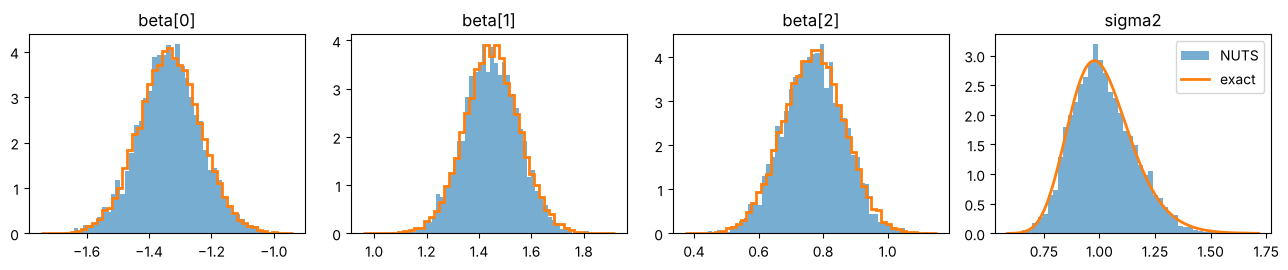

In [9]:
import matplotlib.pyplot as plt
from jax.scipy import stats

exact = cr.sample_exact_posterior(jax.random.PRNGKey(4), X, y, model.hyper, n_chains=1, n_draws=20000)
fig, axes = plt.subplots(1, 4, figsize=(13, 2.8))
for i in range(3):
    axes[i].hist(np.asarray(draws["beta"][..., i]).ravel(), bins=50, density=True, alpha=0.6, label="NUTS")
    axes[i].hist(np.asarray(exact["beta"][..., i]).ravel(), bins=50, density=True, histtype="step", lw=2, label="exact")
    axes[i].set_title(f"beta[{i}]")
axes[3].hist(np.asarray(draws["sigma2"]).ravel(), bins=50, density=True, alpha=0.6, label="NUTS")
grid = np.linspace(float(draws["sigma2"].min()), float(draws["sigma2"].max()), 200)
axes[3].plot(grid, np.exp(cr.log_inv_gamma(grid, an, bn)), lw=2, label="exact")
axes[3].set_title("sigma2"); axes[3].legend()
plt.tight_layout(); plt.show()